In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

IMG_SIZE = 256
BATCH_SIZE = 24
EPOCHS = 25

In [3]:
TRAIN_DIR = r"D:\Tea\Final_Split\train"
VAL_DIR   = r"D:\Tea\Final_Split\val"
TEST_DIR  = r"D:\Tea\Final_Split\test"

In [4]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    seed=SEED
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    seed=SEED
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 8366 files belonging to 6 classes.
Found 1191 files belonging to 6 classes.
Found 1203 files belonging to 6 classes.


In [5]:
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)

Classes: ['Blister Blight', 'Brown Blight', 'Gray Blight', 'Healthy', 'Invalid', 'Red Rust']


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [7]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2)
])

In [8]:
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

In [9]:
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.efficientnet.preprocess_input(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)

x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)

x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = keras.Model(inputs, outputs)

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
checkpoint = ModelCheckpoint(
    "best_efficientnet_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=6,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    min_lr=1e-6
)

csv_logger = CSVLogger("training_metrics.csv")

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stop, reduce_lr, csv_logger]
)

Epoch 1/25


C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 754ms/step - accuracy: 0.8376 - loss: 0.4783
Epoch 1: val_accuracy improved from None to 0.92107, saving model to best_efficientnet_model.keras

Epoch 1: finished saving model to best_efficientnet_model.keras
349/349 ━━━━━━━━━━━━━━━━━━━━ 380s 874ms/step - accuracy: 0.8376 - loss: 0.4783 - val_accuracy: 0.9211 - val_loss: 0.2232 - learning_rate: 0.0010
Epoch 2/25
349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 739ms/step - accuracy: 0.9065 - loss: 0.2715
Epoch 2: val_accuracy improved from 0.92107 to 0.92695, saving model to best_efficientnet_model.keras

Epoch 2: finished saving model to best_efficientnet_model.keras
349/349 ━━━━━━━━━━━━━━━━━━━━ 340s 835ms/step - accuracy: 0.9065 - loss: 0.2715 - val_accuracy: 0.9270 - val_loss: 0.1988 - learning_rate: 0.0010
Epoch 3/25
349/349 ━━━━━━━━━━━━━━━━━━━━ 0s 739ms/step - accuracy: 0.9184 - loss: 0.2343
Epoch 3: val_accuracy improved from 0.92695 to 0.93787, saving model to best_efficientnet_model.keras

Epoch 3: finished savin

In [13]:
test_loss, test_acc = model.evaluate(test_ds)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

51/51 ━━━━━━━━━━━━━━━━━━━━ 28s 539ms/step - accuracy: 0.9684 - loss: 0.0975
Test Accuracy: 0.9684122800827026
Test Loss: 0.0975281298160553


In [14]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([y for x, y in test_ds], axis=0)

predictions = model.predict(test_ds)

y_pred = np.argmax(predictions, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

51/51 ━━━━━━━━━━━━━━━━━━━━ 31s 575ms/step
                precision    recall  f1-score   support

Blister Blight       0.99      0.99      0.99       172
  Brown Blight       0.98      0.93      0.96       213
   Gray Blight       0.84      0.98      0.91       111
       Healthy       0.96      1.00      0.98       283
       Invalid       1.00      1.00      1.00       254
      Red Rust       0.99      0.89      0.94       170

      accuracy                           0.97      1203
     macro avg       0.96      0.96      0.96      1203
  weighted avg       0.97      0.97      0.97      1203



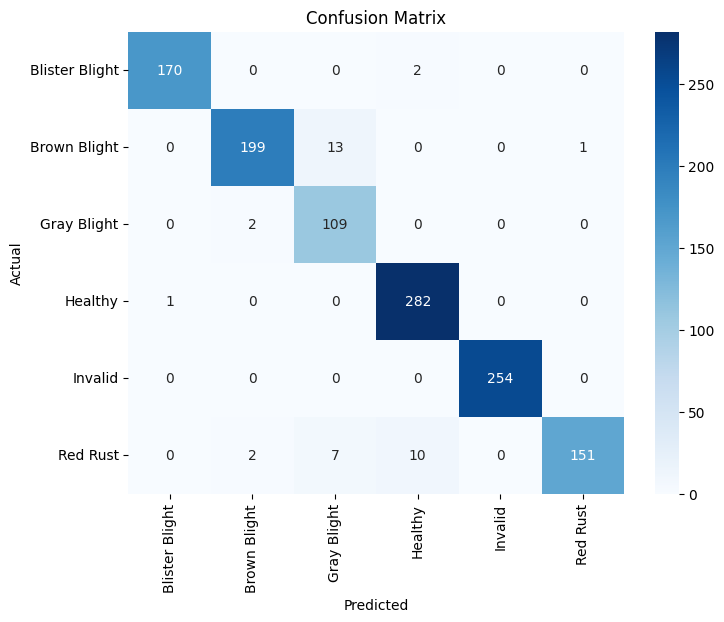

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

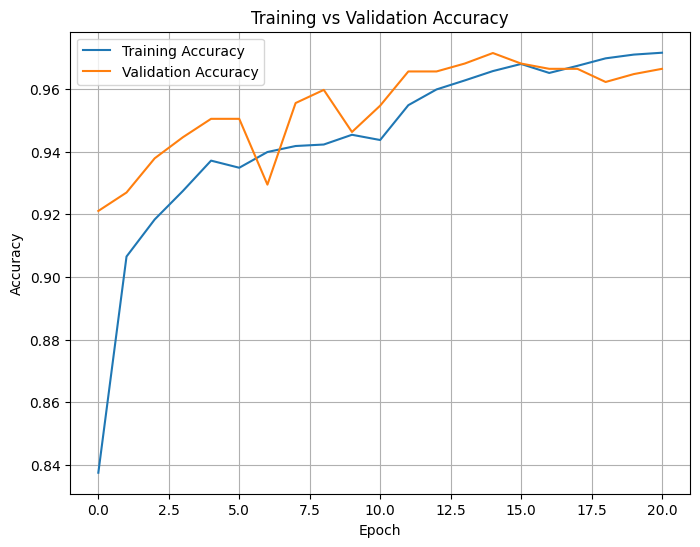

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

log = pd.read_csv("training_metrics.csv")

plt.figure(figsize=(8,6))

plt.plot(log["accuracy"], label="Training Accuracy")
plt.plot(log["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

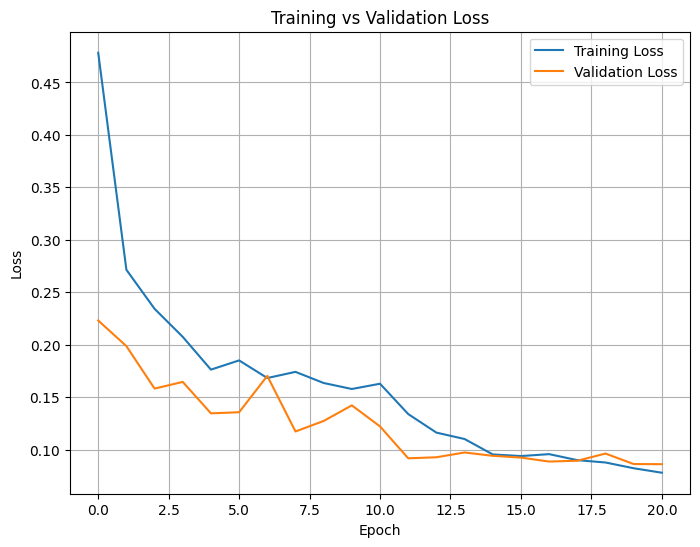

In [16]:
plt.figure(figsize=(8,6))

plt.plot(log["loss"], label="Training Loss")
plt.plot(log["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [17]:
import tensorflow as tf

model = tf.keras.models.load_model("best_efficientnet_model.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("tea_disease_model.tflite", "wb") as f:
    f.write(tflite_model)

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpg4l5r7i4\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpg4l5r7i4\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpg4l5r7i4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  1637345992848: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1637345993616: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1637232846672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232845904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232843024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232847440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232848016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232848208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232845712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1637232847632: TensorSpec(shape=(), dtype=tf.resource

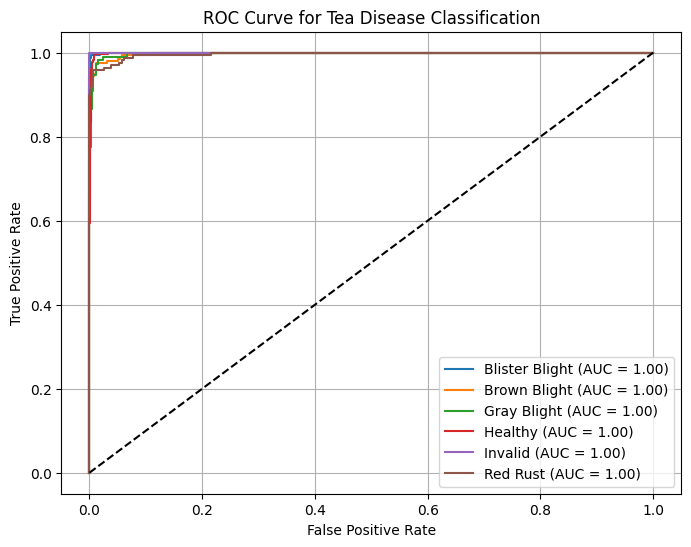

In [18]:
# ROC Curve for Multiclass Classification (Single Cell)

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Convert labels to binary format
y_true_bin = label_binarize(y_true, classes=range(NUM_CLASSES))

# Predicted probabilities
y_score = predictions

# Compute ROC and AUC
fpr = {}
tpr = {}
roc_auc = {}

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})"
    )

# Random classifier reference line
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Tea Disease Classification")

plt.legend()
plt.grid(True)

plt.show()